# NLP1 · Project 2: Word embeddings and compositional encoders on *Bias in Bios*

**Team:** Isha · Diya · Ioana  **Course:** NLP1, University of Amsterdam  **Part:** 2

**The question of this part.** In Part 1 every word was its own, unrelated dimension (*nurse* and *nursing* had
nothing in common). Now we use **pretrained word embeddings**: each word becomes a list of a few hundred numbers,
learned from billions of words of text, in which similar words get similar numbers. We test whether that helps,
first by simply averaging the word vectors of a bio (**embed-and-pool**), then with a **recurrent encoder**
(an LSTM or GRU) that reads the bio word by word, so word order counts.

**What stays the same as Part 1**, so results are directly comparable: the same 257,081 bios, the same 6
cross-validation splits (3 folds × 2 seeds), the same scores (macro-F1, plus the recall gap between women and
men), and the same Bayesian comparison with a ROPE of ±0.01. Part 1's best system, MLP + TF-IDF, scored
**macro-F1 0.754**: that is the bar to beat.

**Notebook map** (one section per "Get to work!" question):
0 Setup · 1 Data recap · 2 Choosing the embedding model · 3 What the embeddings capture · 4 Embed-and-pool ·
5 Recurrent encoder · 6 Search and variance · 7 Error analysis · 8 Fairness · 9 Slide summary · 10 AI log

## 0 · Setup

Same conventions as Part 1: short code cells with a grey "This cell" note, reusable code in `src/bib/`
(new this part: `bib/embeddings.py`), the course's tutorial code in `src/part2/` (never changed). Heavy training
runs on Snellius; this notebook loads their saved results.

> **This cell:** reload our `src/` code automatically when it changes.

In [1]:
# [0a] reload src/ modules automatically when they change
%load_ext autoreload
%autoreload 2

> **This cell:** load libraries, our `bib` code and the tutorial's `part2` code, and set the folders for Part 2 results and figures.

In [2]:
# [0b] imports and paths
import json, pickle, time, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from bib import style, plots, data, evaluation, embeddings as emb   # our code (src/bib/)
import part2                                         # tutorial code for Part 2 (unchanged)

warnings.simplefilter("ignore", category=FutureWarning)
style.apply()
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.precision", 3)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
PART1 = ROOT / "results" / "part1"          # Part 1's saved splits, tokenizer and results
RESULTS = ROOT / "results" / "part2"        # Part 2's saved results (not in git)
FIGURES = ROOT / "figures" / "part2"        # Part 2's figures (in git)
EMB_DIR = ROOT / "data" / "embeddings"      # downloaded pretrained embeddings (not in git: gigabytes)
for d in (RESULTS, FIGURES):
    d.mkdir(parents=True, exist_ok=True)
print("project folder:", ROOT)

project folder: /Users/ishaparanjpe/UvA MSAI/NLP/NLP-Project/Bias-in-Bios/NLP1-Project


## 1 · Data recap

We reuse Part 1's data exactly: the deduplicated training bios and the 6 saved splits
(`results/part1/splits.json`). Using the *same* splits lets us compare a Part 2 model with a Part 1 model split by
split, which is what the Bayesian comparison needs. `dev` and `test` are still untouched; this part we will use
`dev` for error analysis (§7).

> **This cell:** rebuild the pool of 257,081 bios and the 6 splits from Part 1's saved file.

In [3]:
# [1a] the same bios and splits as Part 1
TEXTS, Y, G, FOLDS = data.load_pool(PART1 / "splits.json")
PROFESSIONS = [
    "accountant", "architect", "attorney", "chiropractor", "comedian", "composer",
    "dentist", "dietitian", "dj", "filmmaker", "interior_designer", "journalist",
    "model", "nurse", "painter", "paralegal", "pastor", "personal_trainer",
    "photographer", "physician", "poet", "professor", "psychologist", "rapper",
    "software_engineer", "surgeon", "teacher", "yoga_teacher",
]
K = len(PROFESSIONS)
print(f"{len(TEXTS):,} bios · {K} occupations · {100 * G.mean():.1f}% women · "
      f"{len(FOLDS)} seeds × {len(FOLDS[0])} folds")

257,081 bios · 28 occupations · 46.1% women · 2 seeds × 3 folds


## 2 · Choosing the embedding model (Get to work, question 1)

**What a pretrained word embedding is.** A big table, learned once from billions of words, that gives every word
a vector of numbers. It is trained so that words used in similar contexts get similar vectors (the
*distributional hypothesis*: "you shall know a word by the company it keeps"). We don't train it ourselves; we
download one.

**Two things decide whether a model suits our data:**
1. **Tokenization must match.** The table has an entry per *word as the model's makers cut their text*. If we cut
   our bios differently (e.g. Part 1's BPE pieces like *chiroprac + tor*), most of our tokens won't be found. So
   we switch to a word tokenizer like the tutorial's: lowercase + NLTK.
2. **Coverage.** What share of the words in our bios has a vector? Words without one become "unknown" and all
   look the same to the model.

**The three candidates:**

| model | trained on | words in file | numbers per word |
| --- | --- | --- | --- |
| GloVe 2024 (the tutorial's default) | Wikipedia + newswire | 1,291,147 | 50 |
| fastText wiki-news (the tutorial's alternative) | Wikipedia + web + news | 999,994 | 300 |
| fastText Common Crawl | **Common Crawl**, where our bios come from | 1,999,995 | 300 |

Our expectation: the Common Crawl model should cover our bios best, because it was trained on the same kind of web
text. GloVe is lowercased like our tokens; the fastText files are cased, so we look words up in lowercase (keeping
the most frequent spelling).

### 2.1 Tokenizing for word embeddings

> **This cell:** cut every bio into lowercase words with NLTK, twice: as-is, and with curly quotes and dashes (’ “ ” –) turned into plain ones, because embedding vocabularies are usually written with plain characters. Saved to disk after the first run (about 2 minutes).

In [4]:
# [2a] tokenize every bio once (cached)
TOK_PATH = RESULTS / "tokens_nltk.pkl"
if TOK_PATH.exists():
    TOKENS, TOKENS_RAW = pickle.load(open(TOK_PATH, "rb"))
else:
    t0 = time.time()
    TOKENS = [emb.tokenize(t, normalise_quotes=True) for t in TEXTS]       # what we will use
    TOKENS_RAW = [emb.tokenize(t, normalise_quotes=False) for t in TEXTS]  # for comparison only
    pickle.dump((TOKENS, TOKENS_RAW), open(TOK_PATH, "wb"))
    print(f"tokenized in {time.time() - t0:.0f}s")
COUNTS, COUNTS_RAW = emb.vocab_counts(TOKENS), emb.vocab_counts(TOKENS_RAW)
n_tok = np.array([len(t) for t in TOKENS])
print(f"tokens per bio: median {np.median(n_tok):.0f} (5–95%: {np.percentile(n_tok, 5):.0f}–{np.percentile(n_tok, 95):.0f})")
print(f"distinct words: {len(COUNTS):,} with plain quotes, {len(COUNTS_RAW):,} without")
print("example:", TOKENS[1][:25])

tokens per bio: median 63 (5–95%: 29–133)
distinct words: 327,900 with plain quotes, 325,429 without
example: ['she', 'is', 'able', 'to', 'assess', ',', 'diagnose', 'and', 'treat', 'minor', 'illness', 'conditions', 'and', 'exacerbations', 'of', 'some', 'long', 'term', 'conditions', '.', 'her', 'qualifications', 'include', 'registered', 'general']


### 2.2 Coverage of the three candidates

> **This cell:** for each model, stream its file and keep only the vectors of words that occur in our bios (so even the 2-million-word file needs little memory), then measure coverage. About 5 minutes the first time; the kept vectors are saved for later sections.

In [5]:
# [2b] load only the vectors we need, for each candidate (cached)
EMB = {}
for name, spec in emb.MODELS.items():
    cache = RESULTS / f"emb_{name}.npz"
    if cache.exists():
        z = np.load(cache, allow_pickle=True)
        EMB[name] = dict(words=list(z["words"]), vectors=z["vectors"], file_words=int(z["file_words"]))
        continue
    t0 = time.time()
    keep = emb.words_to_keep(COUNTS) | set(COUNTS_RAW)   # our words + parts of hyphen/slash compounds
    words, vectors, n_lines = emb.load_vectors(EMB_DIR / spec["file"], spec["dims"], keep=keep,
                                               skip_first_line=spec["skip_first_line"])
    np.savez_compressed(cache, words=np.array(words, dtype=object), vectors=vectors, file_words=n_lines)
    EMB[name] = dict(words=words, vectors=vectors, file_words=n_lines)
    print(f"{name}: {n_lines:,} words in file, {len(words):,} of ours found, {time.time() - t0:.0f}s")

> **This cell:** compare the candidates: share of distinct words and of running words covered, counting all tokens and only real words (no numbers or punctuation), with and without plain quotes.

In [6]:
# [2c] coverage table
rows = {}
for name, e in EMB.items():
    known = set(e["words"])
    words_only = Counter({w: c for w, c in COUNTS.items() if emb.is_wordlike(w)})
    cov_all, cov_words = emb.coverage(COUNTS, known), emb.coverage(words_only, known)
    cov_raw = emb.coverage(COUNTS_RAW, known)
    rows[emb.MODELS[name]["label"]] = {
        "words in file": e["file_words"],
        "running words covered (%)": cov_all["token coverage (%)"],
        "... without quote fix (%)": cov_raw["token coverage (%)"],
        "distinct words covered (%)": cov_all["type coverage (%)"],
        "running real words covered (%)": cov_words["token coverage (%)"],
        "distinct real words covered (%)": cov_words["type coverage (%)"],
    }
coverage_table = pd.DataFrame(rows).T
coverage_table.style.format({"words in file": "{:,.0f}"}, precision=2)

,words in file,running words covered (%),... without quote fix (%),distinct words covered (%),running real words covered (%),distinct real words covered (%)
"GloVe 2024, 50-d","1,291,147",98.23,98.25,52.51,98.85,65.51
"fastText wiki-news, 300-d","999,994",98.45,98.66,52.86,99.15,64.74
"fastText Common Crawl, 300-d","1,999,995",98.66,98.87,58.82,99.35,71.24


> **This cell:** check the words that matter most for our task: the 28 occupation names, gender words, and frequent job vocabulary.

In [7]:
# [2d] coverage of task-critical words
job_words = sorted({w for p in PROFESSIONS for w in p.split("_")} | {"paralegal", "chiropractic", "dietitian", "dietician", "neurosurgeon", "rn", "phd", "llc"})
gender_words = ["he", "she", "his", "her", "him", "hers", "himself", "herself", "mr", "mrs", "ms", "husband", "wife", "mother", "father"]
check = pd.DataFrame({emb.MODELS[n]["label"]: {w: ("✓" if w in set(e["words"]) else "—") for w in job_words + gender_words}
                      for n, e in EMB.items()})
print("missing occupation/gender words per model:", {c: int((check[c] == "—").sum()) for c in check})
check[(check == "—").any(axis=1)]

missing occupation/gender words per model: {'GloVe 2024, 50-d': 0, 'fastText wiki-news, 300-d': 0, 'fastText Common Crawl, 300-d': 0}


,"GloVe 2024, 50-d","fastText wiki-news, 300-d","fastText Common Crawl, 300-d"


> **This cell:** list the most frequent words each model is missing, to see *what kind* of words fall through the cracks.

In [8]:
# [2e] what is missing?
missing = {emb.MODELS[n]["label"]: [f"{w} ({c:,})" for w, c in emb.top_missing(COUNTS, set(e["words"]), 15)]
           for n, e in EMB.items()}
pd.DataFrame(missing)

,"GloVe 2024, 50-d","fastText wiki-news, 300-d","fastText Common Crawl, 300-d"
0,"cross/blue (5,459)","'' (26,983)","'' (26,983)"
1,"in-network (4,159)","`` (26,275)","`` (26,275)"
2,"5. (3,457)","cross/blue (5,459)","cross/blue (5,459)"
3,"freeones (2,559)","n't (3,631)","n't (3,631)"
4,"2012. (1,888)","freeones (2,559)","lybrate.com (1,635)"
5,"2013. (1,851)","lybrate.com (1,635)","hospital/clinic (1,216)"
6,".. (1,803)","hospital/clinic (1,216)",complete/partial (490)
7,"2011. (1,779)",and/or (636),cosmetic/ (406)
8,"2010. (1,706)",complete/partial (490),hiv/aids (322)
9,"lybrate.com (1,635)",cosmetic/ (406),self-pay/uninsured (266)


### 2.3 Fixing tokenizer mismatches with a back-off rule

The missing lists show that most gaps are not rare words but **mismatches between our tokenizer and the way each
model's makers cut their text**: GloVe has no hyphenated compounds (*in-network*, *peer-reviewed*: its training text
split them), and the fastText files have no NLTK-style quote tokens (two backticks and two apostrophes) or *n't*.
The back-off rule in `bib.embeddings.backoff` fixes this per model without changing any word: an unknown compound is replaced by its known
parts, NLTK quotes become a plain quote, *n't* becomes *not*.

> **This cell:** measure coverage of running words before and after the back-off rule, per model.

In [9]:
# [2f] coverage with the back-off rule
rows = {}
for name, e in EMB.items():
    known = set(e["words"])
    before = sum(t in known for toks in TOKENS for t in toks) / sum(map(len, TOKENS))
    backed = [emb.backoff(toks, known) for toks in TOKENS]
    after = sum(t in known for toks in backed for t in toks) / sum(map(len, backed))
    rows[emb.MODELS[name]["label"]] = {"running words covered (%)": 100 * before, "with back-off (%)": 100 * after,
                                       "still missing (%)": 100 * (1 - after)}
pd.DataFrame(rows).T.round(2)

,running words covered (%),with back-off (%),still missing (%)
"GloVe 2024, 50-d",98.23,99.04,0.96
"fastText wiki-news, 300-d",98.45,99.13,0.87
"fastText Common Crawl, 300-d",98.66,99.32,0.68


**What we see (2)**
- **Tokenizing:** a bio is a median of **63 tokens** (5–95%: 29–133); our bios contain 327,900 distinct tokens.
- **Coverage is high for all three:** 98.2% (GloVe), 98.5% (wiki-news) and 98.7% (Common Crawl) of *running*
  words have a vector, and **99.0 / 99.1 / 99.3%** with the back-off rule. All 28 occupation words and all 15
  gender words we checked are in every model.
- **Distinct words tell a different story:** only 53–59% of the *distinct* words have a vector. The missing ones are
  rare: names of people and institutions (*o'connor*, *york-presbyterian*, *umdnj-new*), rare medical terms
  (*thighplasty*) and typos (*dietitics*). Together they are under 1% of the text.
- **The gaps are mostly tokenizer mismatches, which the back-off rule fixes:** GloVe has no hyphenated compounds
  (*in-network* 4,159×, *peer-reviewed* 1,274×, *award-winning* 1,100×); the fastText files lack NLTK's quote tokens
  and *n't*.
- **Straightening curly quotes** makes no difference to coverage once back-off is on (99.32 vs 99.33%), but gives
  cleaner tokens: without it NLTK splits *master’s* into *master* + *’* + *s*, creating junk tokens like *s*, *t*, *don*.

**Decision.** Tokenizer = lowercase + plain quotes + NLTK + the back-off rule. **Coverage does not separate the
candidates** (all ≈ 99%), so §3 decides with task-specific tests.

## 3 · What the embeddings capture (Get to work, question 2)

Coverage says *whether* our words have vectors, not whether the vectors are *useful for our task*. We test that
in five ways, each tied to Bias in Bios:

1. **Neighbours:** are the nearest words to *nurse*, *paralegal*, *model* sensible, and do they reveal limitations?
2. **Similarity vs our Part 1 mistakes:** if two occupations are close in embedding space, did our Part 1 model
   also confuse them more often? (If yes, the embeddings encode the same "job similarity" our task struggles with.)
3. **Gender direction:** do the embeddings place occupations along a *he ↔ she* axis the way our data's gender
   shares do? This is the known bias problem of embeddings (Bolukbasi et al., 2016), and it matters for §8.
4. **Analogies:** the classic *a − b + c* test, with gendered examples.
5. **A quick task test:** average each bio's word vectors and train a simple log-linear model, per candidate.

**Cosine similarity**, used throughout: how much two vectors point the same way, from −1 (opposite) to 1 (same
direction), ignoring their length. Two words are "close" when their cosine is high.

> **This cell:** prepare each model's vectors for cosine similarity (scale every vector to length 1), and build one vector per occupation (two-word names like *software engineer* average their two words).

In [10]:
# [3a] unit-length vectors, a frequency filter for neighbours, and one vector per occupation
MIN_FREQ = 20                                            # only words seen ≥ 20 times in our bios can be neighbours
UNIT, INDEX, FREQ_OK = {}, {}, {}
for name, e in EMB.items():
    v = e["vectors"]
    UNIT[name] = v / np.maximum(np.linalg.norm(v, axis=1, keepdims=True), 1e-8)
    INDEX[name] = {w: i for i, w in enumerate(e["words"])}
    FREQ_OK[name] = np.array([COUNTS.get(w, 0) >= MIN_FREQ for w in e["words"]])

def vec(name, word):
    """Unit vector of a word, or of the average of its parts for 'software_engineer'."""
    parts = [UNIT[name][INDEX[name][w]] for w in word.split("_") if w in INDEX[name]]
    v = np.mean(parts, axis=0)
    return v / np.linalg.norm(v)

def neighbours(name, v, k=6, exclude=()):
    sims = UNIT[name] @ v
    sims[~FREQ_OK[name]] = -np.inf
    for w in exclude:
        if w in INDEX[name]: sims[INDEX[name][w]] = -np.inf
    return [EMB[name]["words"][i] for i in np.argsort(-sims)[:k]]

OCC = {name: np.stack([vec(name, p) for p in PROFESSIONS]) for name in EMB}
print({emb.MODELS[n]["label"]: OCC[n].shape for n in EMB})

{'GloVe 2024, 50-d': (28, 50), 'fastText wiki-news, 300-d': (28, 300), 'fastText Common Crawl, 300-d': (28, 300)}


### 3.1 Nearest neighbours

> **This cell:** list the 6 closest words to some occupation words, per model.

In [11]:
# [3b] nearest neighbours of occupation words
probe = ["nurse", "surgeon", "paralegal", "model", "pastor", "dj", "professor"]
pd.DataFrame({emb.MODELS[n]["label"]: {w: ", ".join(neighbours(n, vec(n, w), 6, exclude=[w])) for w in probe}
              for n in EMB})

,"GloVe 2024, 50-d","fastText wiki-news, 300-d","fastText Common Crawl, 300-d"
nurse,"doctor, dentist, nurses, nursing, teacher, pediatrician","nurses, nursing, doctor, midwife, physician, hospital","nurses, nursing, doctor, midwife, hospital, physician"
surgeon,"physician, dentist, neurologist, cardiologist, orthopedic, doctor","surgeons, doctor, neurosurgeon, surgery, physician, surgical","surgeons, neurosurgeon, surgery, doctor, physician, surgical"
paralegal,"psychotherapist, accountant, internist, dentist, anesthesiologist, chiropractor","paralegals, litigator, lawyer, attorney, solicitor, attorneys","paralegals, lawyer, litigator, attorney, attorneys, lawyering"
model,"models, design, concept, introduced, hybrid, standard","models, modeling, prototype, modelling, concept, paradigm","models, modeling, modeled, modelling, modelled, prototype"
pastor,"baptist, reverend, priest, congregation, methodist, preacher","pastors, preacher, congregation, church, priest, reverend","pastors, preacher, congregation, church, ministry, congregations"
dj,"mc, djs, hop, remix, rapper, duo","djs, djing, remix, rapper, mc, remixes","djs, djing, mc, techno, remixes, disco"
professor,"university, associate, harvard, sociology, economics, lecturer","prof., prof, dr., dr, mr., emeritus","prof., prof, dr., lecturer, dr, emeritus"


### 3.2 Does embedding similarity match the mistakes our Part 1 model made?

For every pair of occupations we compare two numbers: how similar their word vectors are (cosine), and how often
our best Part 1 model (MLP + TF-IDF) confused them (the average of "A predicted as B" and "B predicted as A").
**Spearman correlation** measures whether the two rankings agree (1 = same order, 0 = unrelated).

> **This cell:** compute, for all 378 pairs of occupations, the embedding similarity and the Part 1 confusion rate, and how well they agree per model.

{'GloVe 2024, 50-d': 0.555, 'fastText wiki-news, 300-d': 0.414, 'fastText Common Crawl, 300-d': 0.395}


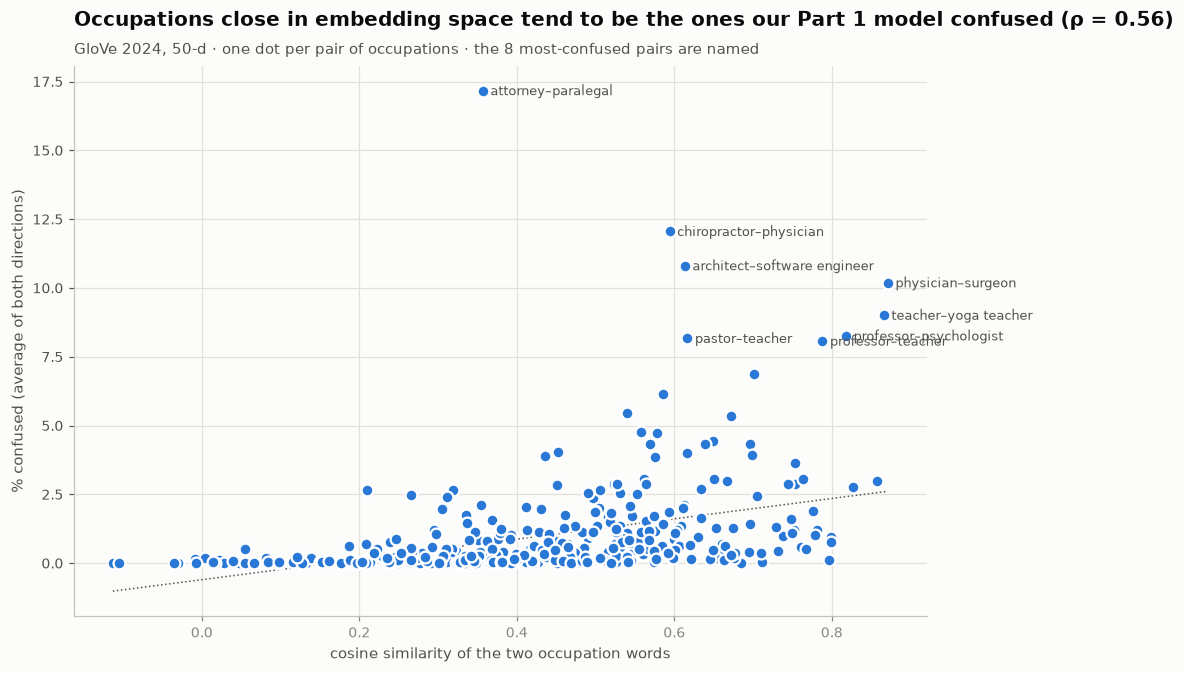

In [12]:
# [3c] embedding similarity vs Part 1 confusions
from scipy.stats import spearmanr, pearsonr
from bib import evaluation
part1_best = pickle.load(open(PART1 / "mlp_tfidf.pkl", "rb"))
cm = evaluation.normalized_confusion(Y, part1_best["oof"][0], K)
iu = np.triu_indices(K, 1)
confusion = ((cm + cm.T) / 2)[iu]                        # symmetric confusion rate per pair
pair_names = [f"{PROFESSIONS[i]}–{PROFESSIONS[j]}" for i, j in zip(*iu)]
SIM = {n: (OCC[n] @ OCC[n].T)[iu] for n in EMB}
agree = pd.Series({emb.MODELS[n]["label"]: spearmanr(SIM[n], confusion)[0] for n in EMB}, name="Spearman ρ")
print(agree.round(3).to_dict())

best_sim = max(agree.index, key=agree.get)
n_best = [n for n in EMB if emb.MODELS[n]["label"] == best_sim][0]
top = set(np.argsort(-confusion)[:8])
fig = plots.labeled_scatter(SIM[n_best], 100 * confusion, [pair_names[i] if i in top else "" for i in range(len(confusion))],
                            f"Occupations close in embedding space tend to be the ones our Part 1 model confused (ρ = {agree[best_sim]:.2f})",
                            f"{best_sim} · one dot per pair of occupations · the 8 most-confused pairs are named",
                            "cosine similarity of the two occupation words", "% confused (average of both directions)")
style.save(fig, FIGURES / "3_similarity_vs_confusion.png"); plt.show()

### 3.3 The gender direction

Following Bolukbasi et al. (2016), we build a **gender direction**: the average of *she − he*, *her − his*,
*woman − man*, *herself − himself*, *mrs − mr*, *mother − father*, *wife − husband*, *girl − boy*, *daughter − son*.
Projecting an occupation word on it gives one number: positive = closer to the female words, negative = closer to
the male words. If these numbers follow the share of women per occupation in *our* data, the embeddings carry the
same gender pattern that Part 1's models amplified.

> **This cell:** build the gender direction per model, project the 28 occupations on it, and correlate with the % of women per occupation in our bios.

correlation of he–she position with % women in our data: {'GloVe 2024, 50-d': np.float64(0.55), 'fastText wiki-news, 300-d': np.float64(0.85), 'fastText Common Crawl, 300-d': np.float64(0.9)}


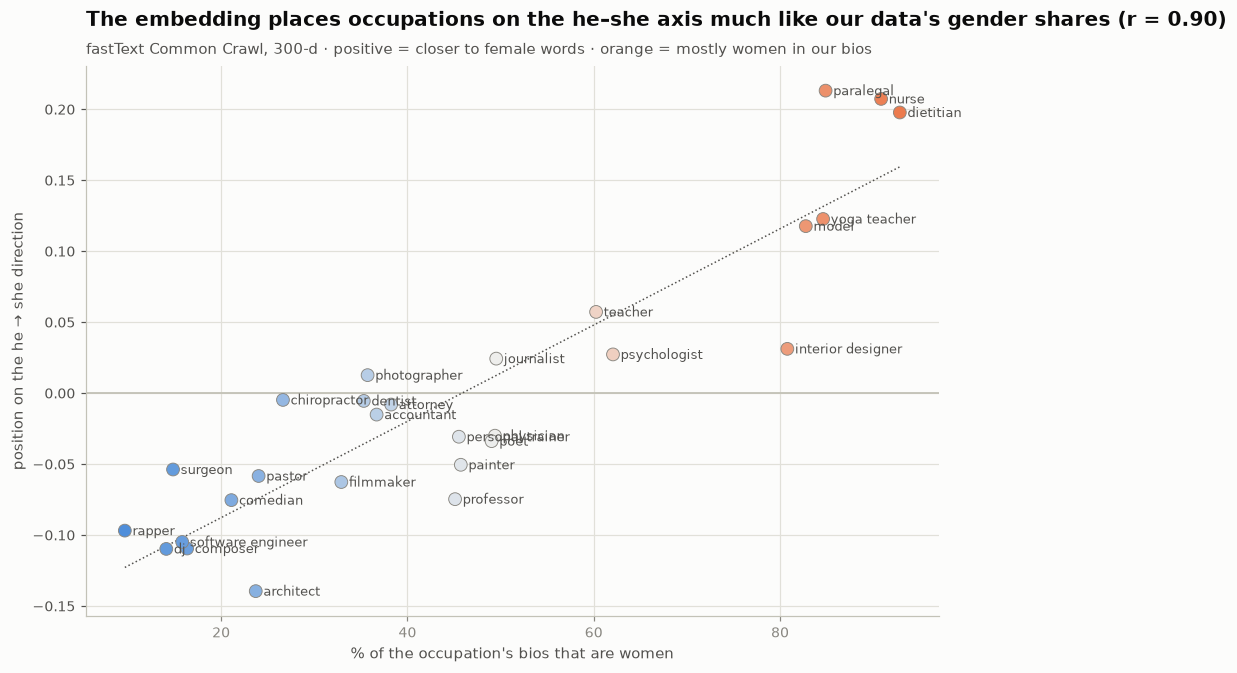

In [13]:
# [3d] occupation words on the he–she axis
from bib import style
PCT_WOMEN = np.array([100 * G[Y == k].mean() for k in range(K)])
PAIRS = [("she", "he"), ("her", "his"), ("woman", "man"), ("herself", "himself"), ("mrs", "mr"),
         ("mother", "father"), ("wife", "husband"), ("girl", "boy"), ("daughter", "son")]
GENDER_PROJ, gcorr = {}, {}
for n in EMB:
    diffs = [UNIT[n][INDEX[n][f]] - UNIT[n][INDEX[n][m]] for f, m in PAIRS if f in INDEX[n] and m in INDEX[n]]
    g = np.mean(diffs, axis=0); g /= np.linalg.norm(g)
    GENDER_PROJ[n] = OCC[n] @ g
    gcorr[emb.MODELS[n]["label"]] = pearsonr(GENDER_PROJ[n], PCT_WOMEN)[0]
print("correlation of he–she position with % women in our data:", {k: round(v, 2) for k, v in gcorr.items()})
n_show = "ft_crawl"
fig = plots.labeled_scatter(PCT_WOMEN, GENDER_PROJ[n_show], PROFESSIONS,
                            f"The embedding places occupations on the he–she axis much like our data's gender shares (r = {gcorr[emb.MODELS[n_show]['label']]:.2f})",
                            f"{emb.MODELS[n_show]['label']} · positive = closer to female words · orange = mostly women in our bios",
                            "% of the occupation's bios that are women", "position on the he → she direction",
                            color_values=PCT_WOMEN, cmap=style.GENDER_DIVERGING, vmin=0, vmax=100, hline=0)
style.save(fig, FIGURES / "3_gender_direction.png"); plt.show()

### 3.4 Analogies

> **This cell:** solve *a − b + c ≈ ?* (e.g. surgeon − he + she) by finding the nearest word to that vector, per model.

In [14]:
# [3e] analogies
ANALOGIES = [("surgeon", "he", "she"), ("nurse", "she", "he"), ("professor", "man", "woman"),
             ("programmer", "man", "woman"), ("paralegal", "woman", "man")]
rows = {}
for a, b, c in ANALOGIES:
    rows[f"{a} − {b} + {c}"] = {}
    for n in EMB:
        if not all(w in INDEX[n] for w in (a, b, c)):
            continue
        v = UNIT[n][INDEX[n][a]] - UNIT[n][INDEX[n][b]] + UNIT[n][INDEX[n][c]]
        rows[f"{a} − {b} + {c}"][emb.MODELS[n]["label"]] = ", ".join(neighbours(n, v / np.linalg.norm(v), 4, exclude=[a, b, c]))
pd.DataFrame(rows).T

,"GloVe 2024, 50-d","fastText wiki-news, 300-d","fastText Common Crawl, 300-d"
surgeon − he + she,"nurse, dentist, physician, pediatrician","surgeons, doctor, nurse, surgery","surgeons, nurse, surgery, doctor"
nurse − she + he,"doctor, physician, nurses, surgeon","doctor, nurses, medic, physician","nurses, doctor, physician, him"
professor − man + woman,"sociology, psychologist, ph.d., researcher","prof., ms., dr., prof","prof., prof, emerita, dr."
programmer − man + woman,"educator, therapist, psychotherapist, entrepreneur","programmers, coder, programming, researcher","programmers, coder, programming, coding"
paralegal − woman + man,"accountant, trainee, internist, technician","paralegals, lawyer, litigator, solicitor","paralegals, lawyer, litigator, attorney"


### 3.5 A quick task test

The real question for question 1 is: *which embeddings help classify bios?* A cheap first answer: represent each
bio by the **average of its word vectors** (this is embed-and-pool, which §4 studies properly), train Part 1's
log-linear model on it, and score one split (seed 0, fold 0). For reference: Part 1's log-linear model on TF-IDF
scored macro-F1 0.753 on this same split.

> **This cell:** average each bio's word vectors (with the back-off rule), train a log-linear model on the training part of seed 0 / fold 0, and score its validation part, for each candidate. About 3–5 minutes.

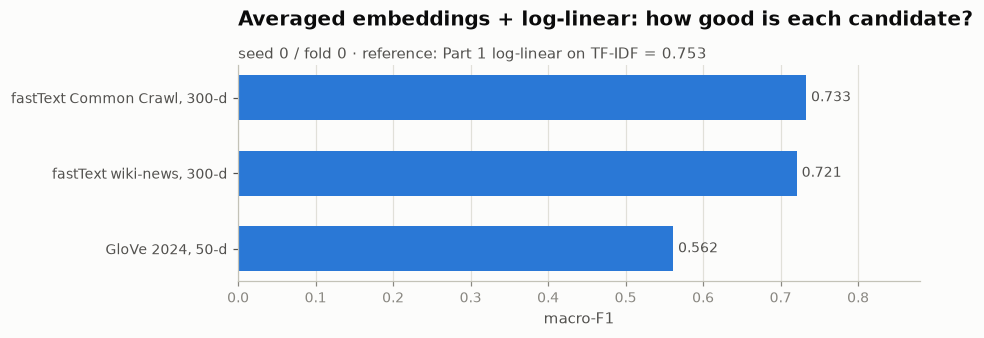

,macro_f1,accuracy,balanced_accuracy,seconds
"GloVe 2024, 50-d",0.562,0.677,0.529,10.298
"fastText wiki-news, 300-d",0.721,0.784,0.704,10.409
"fastText Common Crawl, 300-d",0.733,0.791,0.718,11.392


In [15]:
# [3f] average-of-vectors + log-linear, one split, per candidate
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
tr0, va0 = FOLDS[0][0]
quick = {}
for n, e in EMB.items():
    t0 = time.time()
    X = emb.mean_pool(TOKENS, e["words"], e["vectors"])
    scaler = StandardScaler().fit(X[tr0])
    clf = LogisticRegression(max_iter=500).fit(scaler.transform(X[tr0]), Y[tr0])
    s = evaluation.scores(Y[va0], clf.predict(scaler.transform(X[va0])))
    quick[emb.MODELS[n]["label"]] = {**s, "seconds": time.time() - t0}
quick = pd.DataFrame(quick).T
part1_loglin = pickle.load(open(PART1 / "loglin_tfidf.pkl", "rb"))["scores"].query("seed == 0 and fold == 0")["macro_f1"].iloc[0]
fig = plots.hbars(quick["macro_f1"].sort_values(ascending=False),
                  "Averaged embeddings + log-linear: how good is each candidate?",
                  f"seed 0 / fold 0 · reference: Part 1 log-linear on TF-IDF = {part1_loglin:.3f}", xlabel="macro-F1", fmt="%.3f")
style.save(fig, FIGURES / "3_quick_task_test.png"); plt.show()
quick.round(4)

**What we see (3)**
- **Neighbours ([3b]):** fastText's neighbours are job-relevant (*paralegal* → paralegals, lawyer, litigator,
  attorney); GloVe-50's are vague (*paralegal* → psychotherapist, accountant, internist). Three limitations show up:
  - **one vector per word mixes meanings:** *model* → models, prototype, concept: the *fashion* sense, the one our
    task needs, is drowned out by the technical sense;
  - **spelling variants dominate:** *professor* → prof., prof, dr. (fastText);
  - neighbours are often just other forms of the same word (*surgeon* → surgeons).
- **Similarity vs Part 1's mistakes ([3c]):** occupations that are close in embedding space were confused more often
  by our Part 1 model (Spearman ρ = 0.56 for GloVe, 0.41 wiki-news, 0.40 Common Crawl). The link is moderate: the
  most-confused pair, attorney–paralegal (17%), is only moderately similar. Confusions also come from things
  embeddings don't see, such as templates and the data's label noise.
- **Gender direction ([3d]):** the position of an occupation on the *he → she* axis follows its share of women in our
  bios with **r = 0.90** (Common Crawl), 0.85 (wiki-news), 0.55 (GloVe). Paralegal, nurse and dietitian lie closest to
  the female words; architect, DJ, composer, software engineer and rapper closest to the male words. **The embeddings
  carry the same gender skew as our data before seeing a single bio**, which matters for fairness (§8).
- **Analogies ([3e]):** GloVe gives the classic stereotypes: *surgeon − he + she* → **nurse**; *programmer − man +
  woman* → educator, therapist; *paralegal − woman + man* → accountant. fastText mostly returns other forms of the
  input word (surgeons, paralegals). That's a known quirk of the test, which excludes the input words but not their
  plurals; even so, *nurse* comes second for *surgeon − he + she* in Common Crawl.
- **Quick task test ([3f]):** averaged word vectors + log-linear on one split: **Common Crawl 0.733**, wiki-news 0.721,
  GloVe-50 0.562 macro-F1 (Part 1's log-linear on TF-IDF: 0.753 on the same split). Averaging 50 numbers loses too
  much; 300 do much better, though still a little below TF-IDF with a linear model.

**Decision: fastText Common Crawl, 300-d.** It has the best coverage (99.3%), the best task score (0.733), the same
source as our bios (Common Crawl) and sensible neighbours. The costs to keep in mind: it is the largest file (1.5 GB),
and it has the **strongest gender signal** (r = 0.90), so we check gender gaps in §8. One caveat: GloVe was 50-d against
300-d fastText, so *size* and *training corpus* are mixed in this comparison; §4 tests embedding size separately.

## 4 · Embed-and-pool (Get to work, question 3)

**The idea.** Look up the pretrained vector of every word in a bio, **pool** them into one vector (for example
their average), and give that one vector to a classifier. This is the tutorial's `EmbedAndPoolEncoder`.

![embed-and-pool](../figures/part2/diagrams/embed_and_pool.png)

**What question 3 asks:** which design choices make a real difference (embedding size, architecture,
optimisation), and do pretrained embeddings beat what we had in Part 1 (MLP + TF-IDF, mean macro-F1 **0.754**)?

**How we search: in stages**, so that each comparison changes one thing only:

| stage | what we vary | what stays fixed | systems |
| --- | --- | --- | --- |
| 1 (§4.2) | pooling (mean, max, both) × classifier (log-linear, 1 hidden layer, 2 hidden layers) | frozen fastText, 300 numbers per word | 9 |
| 2 (§4.3) | the embeddings: frozen, fine-tuned or learned from scratch; their size (50, 100, 300); GloVe instead of fastText | stage 1's winner | 5 |
| 3 (§4.4) | the training data: 10%, 30% or all of each training fold | stage 2's frozen, fine-tuned and random-start systems | 6 |
| 4 (§4.5) | best embed-and-pool vs Part 1's best | the same 6 splits | Bayesian test |

**Same training recipe as Part 1**, so differences come from the model, not from the training: AdamW, learning
rate 0.001, batches of 128 bios, at most 20 epochs, **early stopping** on the macro-F1 of an inner 10% hold-out
(stop after 3 epochs without improvement and keep the best epoch). Every system runs on all 6 splits (3 folds ×
2 seeds) and is saved in `results/part2/`. We ran the training from a terminal (`scripts/run_part2.py`, 21 minutes
for all 20 systems on the laptop's CPU); the cells below only load the saved results.

**Words used below**
- *frozen* embeddings: the pretrained vectors are used as they are; only the classifier learns.
- *fine-tuned*: the vectors start pretrained and are trained further on our task.
- *random start* (learned from scratch): the vectors start as random numbers and are learned from our bios only.
  Comparing this with fine-tuning shows what *pretraining* adds.
- *standardise*: shift and scale each of the numbers to mean 0 and spread 1, using the training fold only. Raw
  fastText averages are tiny and uneven; standardising lets one learning rate suit every system.

### 4.1 From words to table rows

A model can't look up a word directly; it looks up a **row number** in the vector table. We turn every bio into a
list of row numbers once (with §2's back-off rule) and save it. Row 0 is `<pad>` (zeros, used to make the bios of a
batch equally long; every model ignores it), row 1 is `<unk>` (the average vector, for words without a vector).

> **This cell:** turn every bio into a list of table row numbers (saved after the first run; seconds), set up the object that trains and caches Part 2 systems, and translate one bio back to check.

In [16]:
# [4a] bios as row numbers in the fastText table
from bib import neural, runs
DATA = runs.Data(Y, G, FOLDS, RESULTS, tokens=TOKENS)
DATA.save_labels()                                     # labels for scripts/run_part2.py (and Snellius)
TABLE, IDS = DATA.table_ids("ft_crawl")
ROWS = ["<pad>", "<unk>"] + list(np.load(RESULTS / "emb_ft_crawl.npz", allow_pickle=True)["words"])
all_ids = np.concatenate(IDS)
print(f"table: {TABLE.shape[0]:,} rows × {TABLE.shape[1]} numbers = {TABLE.size / 1e6:.1f} million numbers")
print(f"{len(all_ids):,} tokens in all bios, {100 * np.mean(all_ids == neural.UNK):.2f}% of them <unk>")
print("first tokens of bio 0:", TOKENS[0][:10])
print("as row numbers:       ", IDS[0][:10].tolist())
print("rows back to words:   ", [ROWS[i] for i in IDS[0][:10]])

table: 202,182 rows × 300 numbers = 60.7 million numbers
17,877,676 tokens in all bios, 0.68% of them <unk>
first tokens of bio 0: ['he', 'is', 'also', 'the', 'project', 'lead', 'of', 'and', 'major', 'contributor']
as row numbers:        [48, 10, 61, 3, 351, 597, 7, 5, 638, 9638]
rows back to words:    ['he', 'is', 'also', 'the', 'project', 'lead', 'of', 'and', 'major', 'contributor']


### 4.2 Stage 1: how to pool, and how big a classifier?

**Three ways to pool** the word vectors of a bio into one vector:
- **mean**: the average (what the tutorial does). Every word counts equally, so the bio's overall topic dominates.
- **max**: for each of the 300 numbers, the largest value anywhere in the bio. One strong word (*paralegal*) can
  set a number on its own, however long the bio is.
- **mean + max** (`meanmax`): both side by side, 600 numbers.

**Three classifiers** on top (all end in a softmax over the 28 occupations):
- **log-linear** (`loglin`): one weight per (number, occupation), 300 × 28 + 28 = 8,428 weights.
- **MLP with 1 hidden layer of 256** (`mlp256`, tanh): it can combine numbers before deciding.
- **MLP with 2 hidden layers of 256** (`mlp256x256`): the shape of the tutorial's `SoftmaxRegressor`.

All nine use **frozen** fastText vectors. Then a bio's pooled vector never changes, so we compute it once and train
only the classifier on it. That is the same model as the tutorial's frozen `EmbedAndPoolEncoder`, but an epoch takes
about a second instead of minutes.

> **This cell:** load the 9 stage-1 systems (trained on all 6 splits by `scripts/run_part2.py --group pool_stage1`; if a result is missing, this cell trains it, about 2–3 minutes per system) and show mean ± spread over the 6 splits.

In [17]:
# [4b] stage 1: 3 poolings × 3 classifiers (frozen fastText)
STAGE1 = runs.group("pool_stage1")
RES = {name: runs.run(name, spec, DATA) for name, spec in STAGE1}

def summarise(names):
    # mean ± std over the 6 splits, plus training cost, one row per system
    s = pd.concat([RES[n]["scores"] for n in names])
    g = s.groupby("system", sort=False)
    cols = ["macro_f1", "accuracy", "balanced_accuracy"]
    out = g[cols].mean().round(4).astype(str) + " ± " + g[cols].std().round(4).astype(str)
    out["best epoch (mean)"] = g["best_epoch"].mean().round(1)
    out["seconds per split"] = g["seconds"].mean().round(0)
    out["weights trained"] = g["params_trained"].first().map("{:,}".format)
    return out

summarise([n for n, _ in STAGE1])

,macro_f1,accuracy,balanced_accuracy,best epoch (mean),seconds per split,weights trained
system,,,,,,
pool-mean-loglin,0.7282 ± 0.0019,0.7883 ± 0.001,0.7079 ± 0.0019,6.7,5.0,"8,428"
pool-mean-mlp256,0.7459 ± 0.0044,0.808 ± 0.0021,0.7325 ± 0.0084,5.8,7.0,"84,252"
pool-mean-mlp256x256,0.7446 ± 0.0041,0.8076 ± 0.0033,0.7332 ± 0.0076,6.2,12.0,"150,044"
pool-max-loglin,0.6519 ± 0.0023,0.7311 ± 0.0009,0.6222 ± 0.0023,8.3,6.0,"8,428"
pool-max-mlp256,0.659 ± 0.0048,0.7435 ± 0.0015,0.6354 ± 0.0073,6.2,7.0,"84,252"
pool-max-mlp256x256,0.6599 ± 0.0033,0.7455 ± 0.0015,0.6416 ± 0.0049,6.8,11.0,"150,044"
pool-meanmax-loglin,0.7307 ± 0.0021,0.7924 ± 0.002,0.7157 ± 0.0028,5.0,5.0,"16,828"
pool-meanmax-mlp256,0.7427 ± 0.0039,0.8066 ± 0.001,0.7271 ± 0.0063,5.0,7.0,"161,052"
pool-meanmax-mlp256x256,0.7447 ± 0.0032,0.8078 ± 0.0011,0.7326 ± 0.0062,6.0,12.0,"226,844"


> **This cell:** show the 9 mean macro-F1 scores as a grid: rows = pooling, columns = classifier.

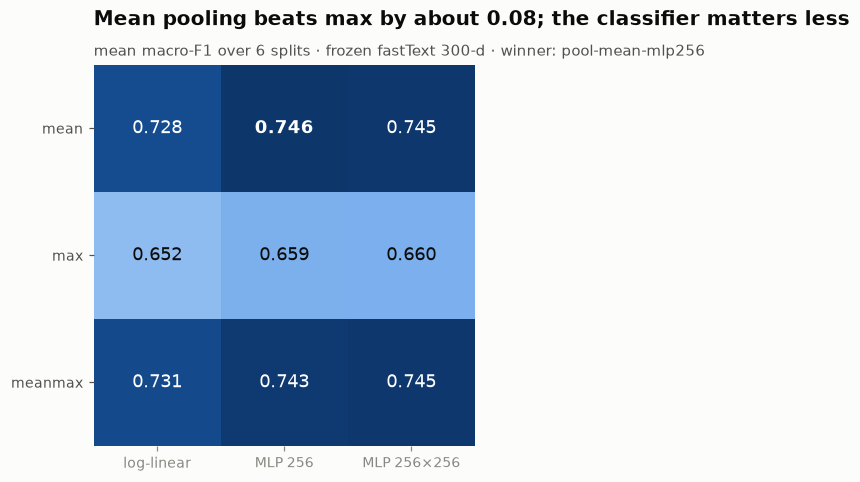

average per pooling:    {'mean': 0.7396, 'max': 0.6569, 'meanmax': 0.7393}
average per classifier: {'log-linear': 0.7036, 'MLP 256': 0.7159, 'MLP 256×256': 0.7164}


In [18]:
# [4c] the stage-1 grid
HEAD = {(): "log-linear", (256,): "MLP 256", (256, 256): "MLP 256×256"}
grid = pd.DataFrame([{"pooling": spec["pooling"], "classifier": HEAD[spec["hidden"]],
                      "macro_f1": RES[n]["scores"]["macro_f1"].mean()} for n, spec in STAGE1])
grid = grid.pivot(index="pooling", columns="classifier", values="macro_f1").loc[["mean", "max", "meanmax"], list(HEAD.values())]
WIN1 = max(STAGE1, key=lambda s: RES[s[0]]["scores"]["macro_f1"].mean())      # (name, spec) of the winner
fig = plots.grid_heatmap(grid, "Mean pooling beats max by about 0.08; the classifier matters less",
                         f"mean macro-F1 over 6 splits · frozen fastText 300-d · winner: {WIN1[0]}")
style.save(fig, FIGURES / "4_stage1_grid.png"); plt.show()
print("average per pooling:   ", grid.mean(axis=1).round(4).to_dict())
print("average per classifier:", grid.mean(axis=0).round(4).to_dict())

> **This cell:** test which stage-1 differences are real, with Part 1's Bayesian test (ROPE ±0.01): mean vs max pooling, a hidden layer, a second hidden layer, adding max to mean.

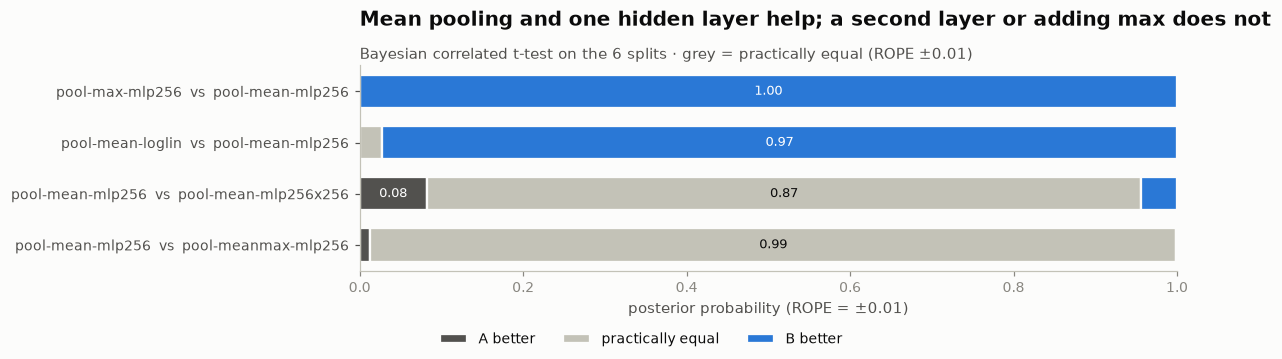

,question,A,B,mean A,mean B,mean diff (B−A),posterior std,P(A better),P(equal),P(B better)
0,mean instead of max pooling?,pool-max-mlp256,pool-mean-mlp256,0.659,0.746,0.087,0.005,0.000,0.000,1.000
1,a hidden layer?,pool-mean-loglin,pool-mean-mlp256,0.728,0.746,0.018,0.003,0.000,0.027,0.973
2,a second hidden layer?,pool-mean-mlp256,pool-mean-mlp256x256,0.746,0.745,-0.001,0.005,0.082,0.875,0.043
3,adding max to mean?,pool-mean-mlp256,pool-meanmax-mlp256,0.746,0.743,-0.003,0.002,0.013,0.986,0.001


In [19]:
# [4d] stage 1: which differences are real?
from part1 import analysis as p1_analysis               # tutorial 1's Bayesian test, as in Part 1 §9
ROPE = 0.01

def fold_scores_of(res):
    return res["scores"].sort_values(["seed", "fold"])["macro_f1"].to_numpy()   # same split order for every system

def compare(pairs, results):
    # one row per (A, B, question): mean difference B − A and the three posterior probabilities
    rows = []
    for a, b, question in pairs:
        post = p1_analysis.BenavoliCorrelatedT(fold_scores_of(results[a]), fold_scores_of(results[b]),
                                               runs=len(FOLDS), names=[a, b])
        p_a, p_eq, p_b = post.probs(ROPE)
        rows.append({"question": question, "A": a, "B": b, "mean A": fold_scores_of(results[a]).mean(),
                     "mean B": fold_scores_of(results[b]).mean(), "mean diff (B−A)": post.mean_diff,
                     "posterior std": post.std, "P(A better)": p_a, "P(equal)": p_eq, "P(B better)": p_b})
    return pd.DataFrame(rows)

STAGE1_CMP = compare([("pool-max-mlp256", "pool-mean-mlp256", "mean instead of max pooling?"),
                      ("pool-mean-loglin", "pool-mean-mlp256", "a hidden layer?"),
                      ("pool-mean-mlp256", "pool-mean-mlp256x256", "a second hidden layer?"),
                      ("pool-mean-mlp256", "pool-meanmax-mlp256", "adding max to mean?")], RES)
fig = plots.comparison_bars(STAGE1_CMP, ROPE, "Mean pooling and one hidden layer help; a second layer or adding max does not",
                            "Bayesian correlated t-test on the 6 splits · grey = practically equal (ROPE ±0.01)")
style.save(fig, FIGURES / "4_stage1_comparisons.png"); plt.show()
STAGE1_CMP.round(3)

**What we see (4.2)**
- **Pooling matters most.** Mean pooling beats max pooling by **0.087** macro-F1 with the same classifier (0.746 vs
  0.659, P(mean better) = 1.00); averaged over the three classifiers, mean 0.740 vs max 0.657. Max keeps only the most
  extreme value of each number, so a single unusual word can decide it; the average keeps the bio's overall topic.
- **Adding max to mean adds nothing:** −0.003 with the 1-layer MLP, practically equal (P = 0.99).
- **One hidden layer helps:** log-linear 0.728 → MLP 0.746 (+0.018, P(better) = 0.97). A bio is now 300 dense numbers,
  each mixing many meanings; the hidden layer can combine them before deciding.
- **A second hidden layer does not:** 0.745 vs 0.746, practically equal (P = 0.88), at almost twice the training time
  (12 vs 7 s per split) and 150,044 instead of 84,252 weights. The tutorial's two-layer `SoftmaxRegressor` shape is not
  needed here; Part 1 found the same (a second layer did not beat one).
- **The 6 splits agree closely** (spread 0.002–0.005 per system), so the test can separate differences of about 0.01.
- **Winner: `pool-mean-mlp256`, macro-F1 0.746**, just below Part 1's best (0.754). It is cheap: 7 s per split and 84,252
  trained weights, against 1.28 million for Part 1's MLP.

### 4.3 Stage 2: train the embeddings? Does their size matter?

With stage 1's winner fixed, we change only the embeddings:

| system (suffix) | embeddings | numbers per word | what it tests |
| --- | --- | --- | --- |
| stage 1's winner | fastText, frozen | 300 | the reference |
| `-finetune` | fastText, trained further | 300 | does adapting the vectors to our task help? |
| `-random` | random start, learned from our bios only | 300 | **does pretraining help at all?** |
| `-100d`, `-50d` | fastText shrunk with PCA | 100, 50 | does size matter (same training text)? |
| `-glove50` | GloVe, frozen | 50 | does the training text matter (same size as `-50d`)? |

**PCA** (principal component analysis) keeps the 50 or 100 directions along which the word vectors differ most:
the best 50- or 100-number summary of the same vectors. Comparing fastText-50 with GloVe-50 fixes the problem from
§3, where GloVe was both smaller *and* trained on different text.

Trained embeddings add the whole table to the weights being learned (202,182 rows × 300 = 60.7 million numbers,
against tens of thousands for the classifier). Each batch only updates the rows of its own words ("sparse" updates),
which keeps this fast on a CPU.

> **This cell:** load the 5 stage-2 systems (run by `scripts/run_part2.py --group pool_stage2`; about 3 minutes each if missing) and compare them with stage 1's winner.

In [20]:
# [4e] stage 2: trained embeddings and embedding size (stage-1 winner fixed)
BEST1 = {k: WIN1[1][k] for k in ("pooling", "hidden")}
STAGE2 = runs.group("pool_stage2", BEST1)
RES.update({name: runs.run(name, spec, DATA) for name, spec in STAGE2})
summarise([WIN1[0]] + [n for n, _ in STAGE2])

,macro_f1,accuracy,balanced_accuracy,best epoch (mean),seconds per split,weights trained
system,,,,,,
pool-mean-mlp256,0.7459 ± 0.0044,0.808 ± 0.0021,0.7325 ± 0.0084,5.8,7.0,"84,252"
pool-mean-mlp256-finetune,0.7624 ± 0.0031,0.8211 ± 0.0014,0.7526 ± 0.0101,1.8,32.0,"60,738,852"
pool-mean-mlp256-random,0.7311 ± 0.0025,0.8041 ± 0.0014,0.715 ± 0.0043,3.3,41.0,"60,738,852"
pool-mean-mlp256-50d,0.6683 ± 0.0029,0.7598 ± 0.0016,0.6447 ± 0.0059,10.3,6.0,"20,252"
pool-mean-mlp256-100d,0.7234 ± 0.0033,0.7909 ± 0.0036,0.7082 ± 0.0046,8.8,6.0,"33,052"
pool-mean-mlp256-glove50,0.5863 ± 0.006,0.71 ± 0.0042,0.5574 ± 0.0071,10.5,6.0,"20,252"


> **This cell:** plot every split's score per system (dots) and the mean (bar), with Part 1's best system as a dashed line.

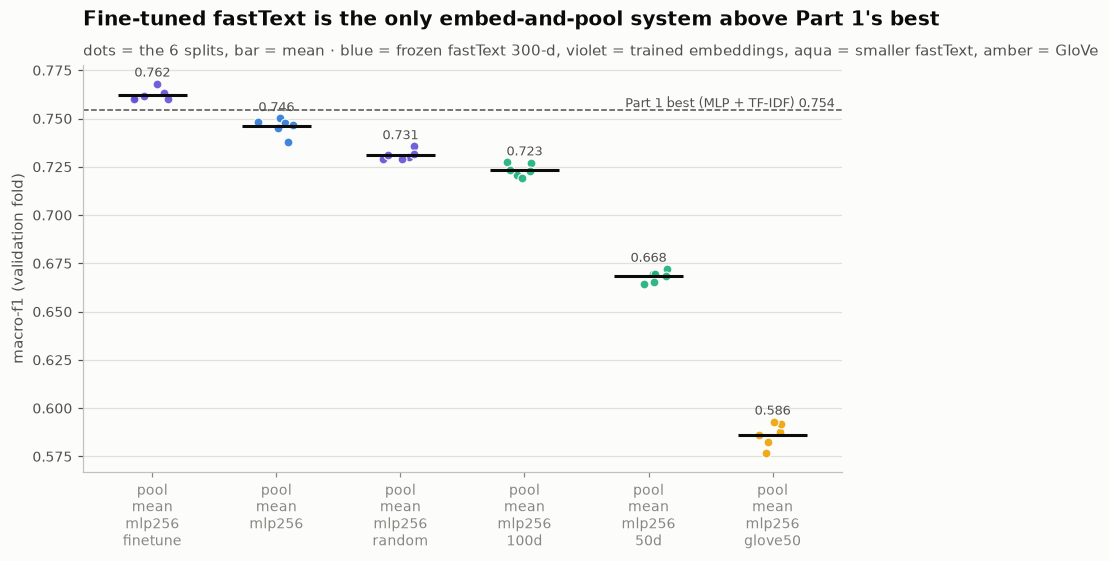

In [21]:
# [4f] stage 2 at a glance
P1_BEST = pickle.load(open(PART1 / "mlp_tfidf.pkl", "rb"))
P1_MEAN = P1_BEST["scores"]["macro_f1"].mean()
order = sorted([WIN1[0]] + [n for n, _ in STAGE2], key=lambda n: -RES[n]["scores"]["macro_f1"].mean())
colors = {n: style.ACCENT for n in order}                                     # blue: frozen fastText 300-d
colors.update({n: style.ARCH_COLORS["mlp"] for n in order if "finetune" in n or "random" in n})   # violet: trained
colors.update({n: style.ARCH_COLORS["loglin"] for n in order if n.endswith("d")})                 # aqua: smaller
colors.update({n: style.ARCH_COLORS["deep"] for n in order if "glove" in n})                       # amber: GloVe
fig = plots.fold_strip(pd.concat([RES[n]["scores"] for n in order]), order, "Fine-tuned fastText is the only embed-and-pool system above Part 1's best",
                       "dots = the 6 splits, bar = mean · blue = frozen fastText 300-d, violet = trained embeddings, "
                       "aqua = smaller fastText, amber = GloVe", colors=colors, ref=P1_MEAN,
                       ref_label=f"Part 1 best (MLP + TF-IDF) {P1_MEAN:.3f}")
style.save(fig, FIGURES / "4_stage2_scores.png"); plt.show()

> **This cell:** test which stage-2 differences are real (same Bayesian test and ROPE as [4d]).

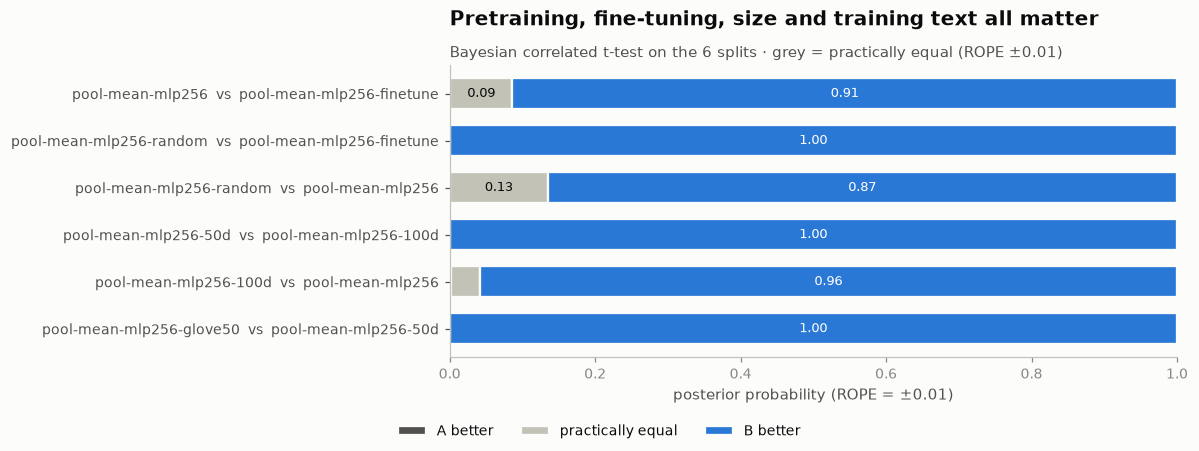

,question,A,B,mean A,mean B,mean diff (B−A),posterior std,P(A better),P(equal),P(B better)
0,fine-tune the vectors?,pool-mean-mlp256,pool-mean-mlp256-finetune,0.746,0.762,0.016,0.004,0.001,0.086,0.914
1,pretrained start instead of random?,pool-mean-mlp256-random,pool-mean-mlp256-finetune,0.731,0.762,0.031,0.001,0.000,0.000,1.000
2,frozen pretrained vs learned from scratch?,pool-mean-mlp256-random,pool-mean-mlp256,0.731,0.746,0.015,0.004,0.001,0.134,0.865
3,100 instead of 50 numbers per word?,pool-mean-mlp256-50d,pool-mean-mlp256-100d,0.668,0.723,0.055,0.002,0.000,0.000,1.000
4,300 instead of 100 numbers per word?,pool-mean-mlp256-100d,pool-mean-mlp256,0.723,0.746,0.023,0.006,0.001,0.040,0.959
5,"fastText instead of GloVe, both 50?",pool-mean-mlp256-glove50,pool-mean-mlp256-50d,0.586,0.668,0.082,0.004,0.000,0.000,1.000


In [22]:
# [4g] stage 2: which differences are real?
W = WIN1[0]
STAGE2_CMP = compare([(W, f"{W}-finetune", "fine-tune the vectors?"),
                      (f"{W}-random", f"{W}-finetune", "pretrained start instead of random?"),
                      (f"{W}-random", W, "frozen pretrained vs learned from scratch?"),
                      (f"{W}-50d", f"{W}-100d", "100 instead of 50 numbers per word?"),
                      (f"{W}-100d", W, "300 instead of 100 numbers per word?"),
                      (f"{W}-glove50", f"{W}-50d", "fastText instead of GloVe, both 50?")], RES)
fig = plots.comparison_bars(STAGE2_CMP, ROPE, "Pretraining, fine-tuning, size and training text all matter",
                            "Bayesian correlated t-test on the 6 splits · grey = practically equal (ROPE ±0.01)")
style.save(fig, FIGURES / "4_stage2_comparisons.png"); plt.show()
STAGE2_CMP.round(3)

> **This cell:** draw the training curves of seed 0 / fold 0 for frozen, fine-tuned and random-start embeddings: how fast does each learn, and when does it start to memorise?

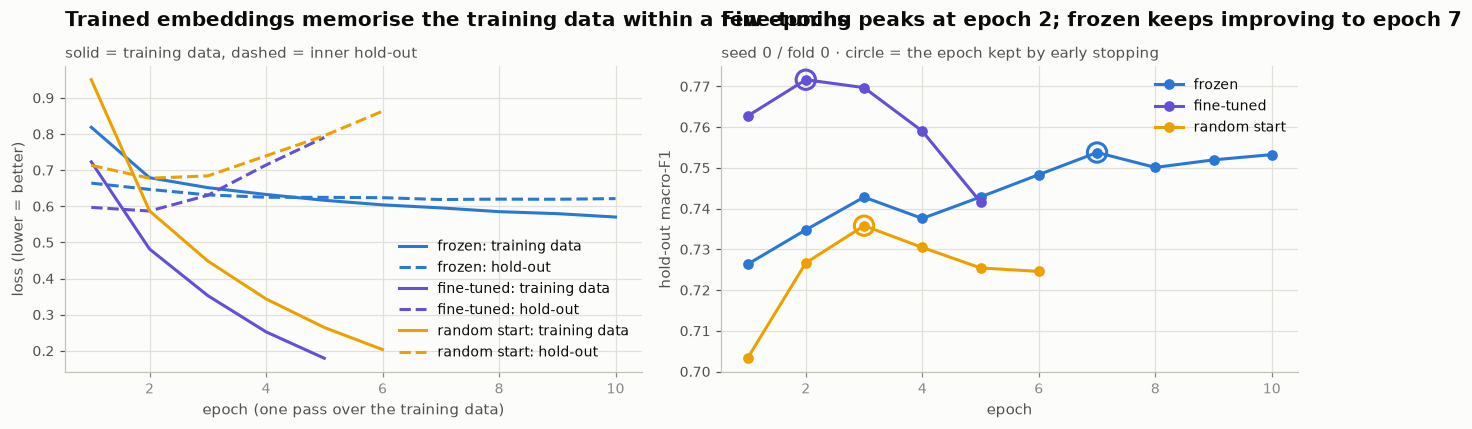

,best epoch,epochs run,best hold-out macro-F1,final training loss
frozen,7.0,10.0,0.754,0.570
fine-tuned,2.0,5.0,0.772,0.179
random start,3.0,6.0,0.736,0.203


In [23]:
# [4h] training curves: frozen vs trained embeddings
trio = {WIN1[0]: "frozen", f"{WIN1[0]}-finetune": "fine-tuned", f"{WIN1[0]}-random": "random start"}
hist = {label: RES[n]["history"][(0, 0)] for n, label in trio.items()}
fig = plots.training_curves(hist, colors={"frozen": style.ACCENT, "fine-tuned": style.ARCH_COLORS["mlp"],
                                          "random start": style.ARCH_COLORS["deep"]},
                            titles=(("Trained embeddings memorise the training data within a few epochs", "solid = training data, dashed = inner hold-out"),
                                    ("Fine-tuning peaks at epoch 2; frozen keeps improving to epoch 7", "seed 0 / fold 0 · circle = the epoch kept by early stopping")))
style.save(fig, FIGURES / "4_training_curves.png"); plt.show()
pd.DataFrame({label: {"best epoch": int(np.argmax([h["holdout_macro_f1"] for h in hist[label]])) + 1,
                      "epochs run": len(hist[label]),
                      "best hold-out macro-F1": max(h["holdout_macro_f1"] for h in hist[label]),
                      "final training loss": hist[label][-1]["train_loss"]} for label in hist}).T.round(3)

**What we see (4.3)**
- **Fine-tuning helps:** letting the vectors change gives **0.762**, vs 0.746 frozen (+0.016, P(better) = 0.91). It is the
  only embed-and-pool system above Part 1's best (0.754).
- **Pretraining helps:** the same model learning its vectors from scratch (random start) reaches only 0.731: 0.031 below
  fine-tuning (P = 1.00), and also below the frozen pretrained vectors (−0.015, P(frozen better) = 0.87). Both trained
  60.7 million weights; the only difference is where the vectors started.
- **Trained embeddings overfit fast ([4h]):** by their last epoch the training loss is 0.18 (fine-tuned) and 0.20
  (random start), against 0.57 for frozen, while their hold-out loss rises after epoch 2. Fine-tuning peaks at epoch 2
  (on average epoch 1.8 over the 6 splits); frozen keeps improving until epoch 7. Early stopping on the hold-out is
  what keeps fine-tuning useful.
- **Size matters:** the same fastText vectors shrunk with PCA score 0.668 with 50 numbers, 0.723 with 100 and 0.746 with
  300 (both steps P(better) ≥ 0.96).
- **The training text matters as much, at equal size:** fastText-50 0.668 vs GloVe-50 0.586 (+0.082, P = 1.00). So the
  §3 gap between GloVe-50 and fastText-300 had two roughly equal parts: about 0.08 from the corpus and 0.08 from size
  (50 → 300 numbers).
- **Cost:** trained embeddings take 32–41 s per split instead of 7 s; still cheap.

### 4.4 Less training data: when does pretraining matter most?

The tutorial asks when knowledge from pretraining should make a difference, and suggests training on less data to find
out. We train stage 2's three systems (frozen, fine-tuned and random-start vectors) on **10% and 30%** of each training
fold (a stratified sample, so every occupation keeps its share) and score them on the same, full validation folds.

What we expect: learned from scratch, a word's vector improves only when the word appears in the training bios; with
less data, rarer words are seen too few times. Pretrained vectors already know them, so their advantage should grow.

> **This cell:** load the 6 data-size systems (`scripts/run_part2.py --group pool_datasize`, about 5 minutes on the CPU if missing), draw macro-F1 against the share of training data, and test the pretraining gain at each size.

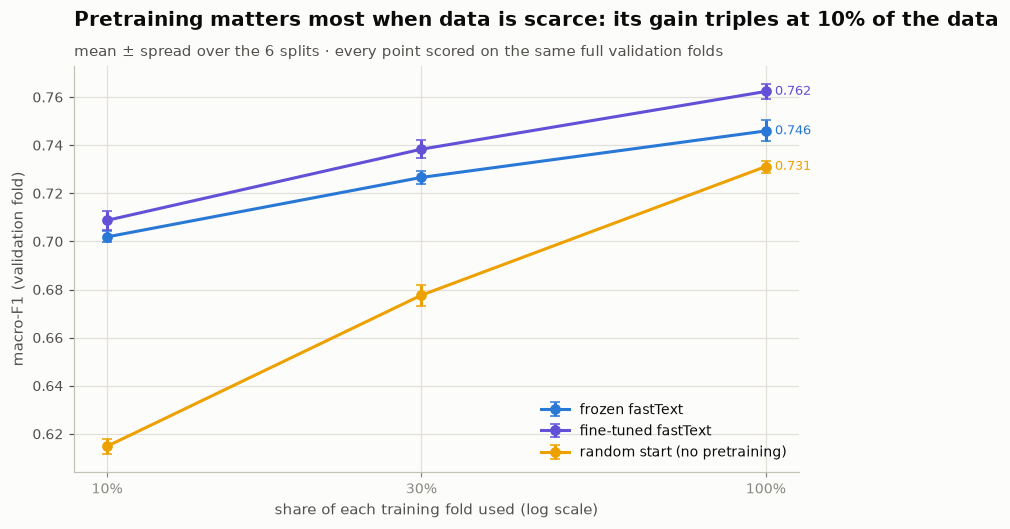

pct                            10% of data  30% of data  100% of data
family                                                               
fine-tuned fastText                  0.709        0.738         0.762
frozen fastText                      0.702        0.727         0.746
random start (no pretraining)        0.615        0.678         0.731 



,question,mean A,mean B,mean diff (B−A),P(A better),P(equal),P(B better)
0,"pretraining gain, 10% of the data",0.615,0.709,0.094,0.0,0.0,1.0
1,"pretraining gain, 30% of the data",0.678,0.738,0.061,0.0,0.0,1.0
2,"pretraining gain, all data",0.731,0.762,0.031,0.0,0.0,1.0


In [24]:
# [4i] data-size curve: frozen, fine-tuned and random-start vectors on 10%, 30% and 100% of the training data
SIZE = runs.group("pool_datasize")
RES.update({name: runs.run(name, spec, DATA) for name, spec in SIZE})
FAMILY = {"frozen": "frozen fastText", "finetune": "fine-tuned fastText", "random": "random start (no pretraining)"}
full = [(n, RES[n]["hp"]) for n in (W, f"{W}-finetune", f"{W}-random")]
SIZE_TABLE = pd.DataFrame([{"family": FAMILY[spec["embeddings"]], "pct": 100 * spec["train_frac"],
                            "mean": RES[n]["scores"]["macro_f1"].mean(), "std": RES[n]["scores"]["macro_f1"].std()}
                           for n, spec in SIZE + full])
fig = plots.data_size_lines(SIZE_TABLE, "Pretraining matters most when data is scarce: its gain triples at 10% of the data",
                            "mean ± spread over the 6 splits · every point scored on the same full validation folds",
                            colors={FAMILY["frozen"]: style.ACCENT, FAMILY["finetune"]: style.ARCH_COLORS["mlp"],
                                    FAMILY["random"]: style.ARCH_COLORS["deep"]})
style.save(fig, FIGURES / "4_data_size.png"); plt.show()
print(SIZE_TABLE.pivot(index="family", columns="pct", values="mean").round(3).rename(columns=lambda p: f"{p:g}% of data").to_string(), "\n")
DS_CMP = compare([(f"{W}-random-data10", f"{W}-finetune-data10", "pretraining gain, 10% of the data"),
                  (f"{W}-random-data30", f"{W}-finetune-data30", "pretraining gain, 30% of the data"),
                  (f"{W}-random", f"{W}-finetune", "pretraining gain, all data")], RES)
DS_CMP[["question", "mean A", "mean B", "mean diff (B−A)", "P(A better)", "P(equal)", "P(B better)"]].round(3)

**What we see (4.4)**
- **Pretraining matters more as data shrinks.** Fine-tuned fastText beats vectors learned from scratch by **0.094** with
  10% of the training data (0.709 vs 0.615), 0.061 with 30% and 0.031 with all of it (each P(better) = 1.00). With a
  tenth of the data, the gain is three times as large.
- **Pretrained vectors cope well with little data:** frozen fastText trained on 10% of the bios still reaches 0.702,
  only 0.044 below its full-data score (0.746). Learning from scratch loses 0.116 (0.731 → 0.615).
- **Pretrained vectors on 10% of the data (0.702–0.709) beat learning from scratch on 30% (0.678).**
- **Fine-tuning adds a little at every size** (0.709 vs 0.702 at 10%, 0.738 vs 0.727 at 30%, 0.762 vs 0.746 with all data).
- **Answer to the tutorial's question:** knowledge from pretraining helps most when task data is scarce. Learned from
  scratch, a word's vector only improves when the word shows up in our training bios, and with less data many words
  show up too rarely. With all the training bios the gap shrinks but does not close.

### 4.5 Do pretrained embeddings beat Part 1?

We compare the best embed-and-pool system with Part 1's best (MLP + TF-IDF) and with Part 1's log-linear + TF-IDF,
on the **same 6 splits**, with the same Bayesian test as Part 1: the correlated t-test of Benavoli et al. (2017),
which accounts for the splits sharing training data. The **ROPE** (region of practical equivalence) is ±0.01:
a difference smaller than 1 macro-F1 point counts as "practically equal".

> **This cell:** compute, for each comparison, the probability that Part 1's system is better, that both are practically equal, or that the embed-and-pool system is better; then draw the main comparison's posterior.

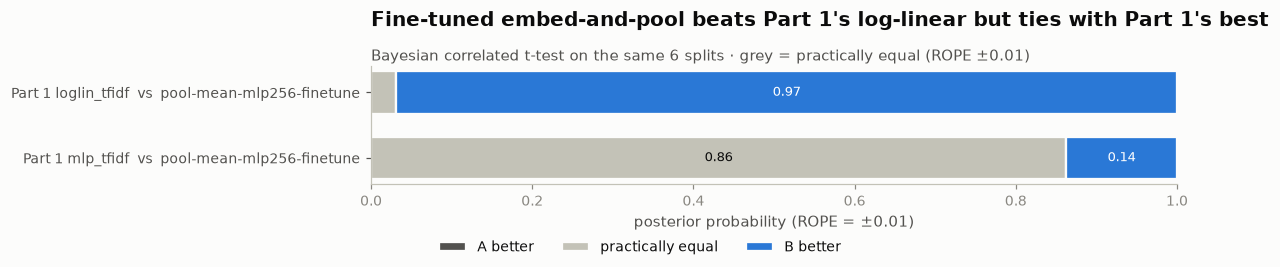

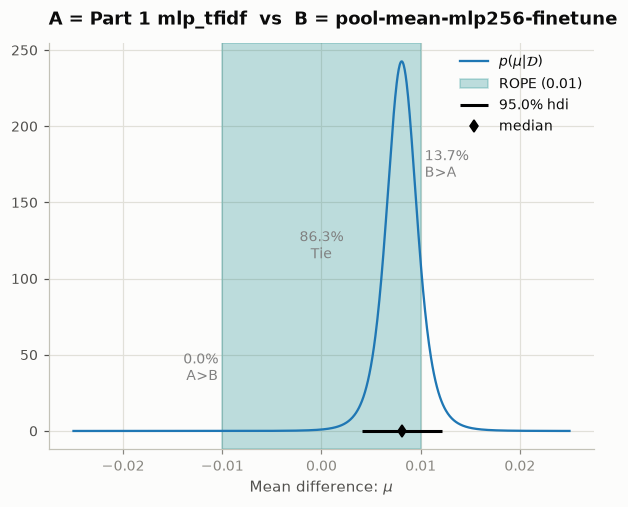

,question,A,B,mean A,mean B,mean diff (B−A),posterior std,P(A better),P(equal),P(B better)
0,better than Part 1?,Part 1 loglin_tfidf,pool-mean-mlp256-finetune,0.749,0.762,0.013,0.001,0.0,0.032,0.968
1,better than Part 1?,Part 1 mlp_tfidf,pool-mean-mlp256-finetune,0.754,0.762,0.008,0.002,0.0,0.863,0.137


In [25]:
# [4j] best embed-and-pool vs Part 1 (Bayesian, ROPE 0.01)
BEST4 = max(RES, key=lambda n: RES[n]["scores"]["macro_f1"].mean())
PART1_RES = {f"Part 1 {p1}": pickle.load(open(PART1 / f"{p1}.pkl", "rb")) for p1 in ("loglin_tfidf", "mlp_tfidf")}
CMP4 = compare([(p1, BEST4, "better than Part 1?") for p1 in PART1_RES], {**PART1_RES, **RES})
POST = p1_analysis.BenavoliCorrelatedT(fold_scores_of(PART1_RES["Part 1 mlp_tfidf"]), fold_scores_of(RES[BEST4]),
                                       runs=len(FOLDS), names=["Part 1 mlp_tfidf", BEST4])
fig = plots.comparison_bars(CMP4, ROPE, "Fine-tuned embed-and-pool beats Part 1's log-linear but ties with Part 1's best",
                            "Bayesian correlated t-test on the same 6 splits · grey = practically equal (ROPE ±0.01)")
style.save(fig, FIGURES / "4_vs_part1.png"); plt.show()
fig, ax = POST.plot(ROPE)
ax.set_title(f"A = Part 1 mlp_tfidf  vs  B = {BEST4}", fontsize=11.5)
style.save(fig, FIGURES / "4_posterior_vs_part1.png"); plt.show()
CMP4.round(3)

**What we see (4.4)**
- **Better than Part 1's log-linear + TF-IDF:** 0.762 vs 0.749 (+0.013, P(better) = 0.97).
- **Not clearly better than Part 1's best, MLP + TF-IDF:** 0.762 vs 0.754 (+0.008). The difference sits inside our ROPE:
  P(practically equal) = 0.86, P(embed-and-pool better) = 0.14, P(Part 1 better) = 0.00.
- **Why so close?** Many bios contain a telling word (Part 1's keyword probe, §1.9: 79% of dentist bios say
  *dentist*), and TF-IDF already captures those. Embeddings add that similar words look alike (*nurse*, *nursing*, *midwife*), which helps a little,
  but word order is still ignored. That is what the recurrent encoder in §5 adds.
- **So, did pretrained embeddings add to our design?** Yes, in two ways: pretrained vectors beat vectors learned from
  our bios alone (+0.031 when fine-tuned), and a frozen, 84k-weight classifier on them gets within 0.008 of Part 1's best.
  But they do not beat Part 1's best by a margin that matters (ROPE ±0.01).

**Decision.** Our best embed-and-pool system is `pool-mean-mlp256-finetune` (mean pooling, fine-tuned fastText, one
hidden layer of 256): macro-F1 **0.762**, practically equal to Part 1's best. It is the bar for the LSTM/GRU in §5.
Because trained embeddings overfit within 2 epochs, §5 needs early stopping and regularisation (word dropout), and
should compare frozen, fine-tuned and random-start embeddings, as question 4 asks.

## 5 · Recurrent encoder: LSTM / GRU (Get to work, question 4)

**The idea.** Embed-and-pool ignores word order. A **recurrent** encoder reads the bio word by word and keeps a
**state**: a list of numbers (here 128) that summarises what it has read so far. The same small network (the *cell*)
updates the state at every word, so it works for bios of any length. This is the tutorial's `LSTMEncoder`.

![LSTM / GRU](../figures/part2/diagrams/rnn.png)

**What question 4 asks:** which design choices matter; the effect of data size and of frozen vs trainable
embeddings; whether we struggle with overfitting; and whether this beats embed-and-pool (our bar: **0.762**, §4).

**Words used below**
- *LSTM* (long short-term memory) and *GRU* (gated recurrent unit): two common cells. Both use *gates*, small switches
  learned from data that decide what to keep, forget and add at each word. A GRU has fewer gates, so fewer weights.
- *bidirectional*: a second cell reads the bio from right to left; the two final states are joined.
- *readout*: how the bio vector is taken from the states. *last* = the state after the last word (the tutorial);
  *mean* = the average of the states after every word, so the start of a long bio counts as much as the end.
- *word dropout*: while training, each word is blanked with some probability (as in the tutorial's `LSTMEncoder`),
  so the model cannot rely on any single word.
- *packed sequences*: bios of different lengths share a batch; packing lets the cell skip the padding.

**Plan, in two stages** (same 6 splits, training recipe and classifier as §4, so only the encoder differs):

| stage | systems | what varies |
| --- | --- | --- |
| 1 | 8 | the tutorial's LSTM (128 numbers of state, left to right, last state, frozen fastText, no word dropout), plus 7 versions that each change one thing: GRU · bidirectional · 256 numbers of state · mean readout · fine-tuned vectors · random-start vectors · word dropout 0.25 |
| 2 | up to 7 | stage 1's useful changes combined; then frozen, fine-tuned and random-start vectors; and 10% / 30% of the training data, for its vectors vs random start |

**Where it runs.** Measured with `scripts/run_part2.py --quick` on 18 Nov: one epoch over the 154,248 training bios
of a split takes 26 s for the base LSTM on the Mac's GPU (MPS). That is about 0.4–0.8 hours per system with frozen
vectors and about 2 hours with trained vectors, for all 6 splits. So the runs go to a teammate's NVIDIA GPU
(`scripts/run_part2.py --group rnn_stage1`); this notebook only loads the saved results.

### 5.1 Which systems have results?

> **This cell:** list the planned LSTM/GRU systems of stage 1 and show which already have results (with their mean macro-F1 over the 6 splits).

In [26]:
# [5a] which LSTM/GRU systems have results?
RNN1 = runs.group("rnn_stage1")
status = []
for name, spec in RNN1:
    done = (RESULTS / f"{name}.pkl").exists()
    res = runs.load(name, RESULTS) if done else None
    status.append({"system": name, "results": "yes" if done else "not yet",
                   "macro-F1 (mean of 6 splits)": res["scores"]["macro_f1"].mean() if done else np.nan,
                   "seconds per split": res["scores"]["seconds"].mean() if done else np.nan})
pd.DataFrame(status).set_index("system").round(4)

,results,macro-F1 (mean of 6 splits),seconds per split
system,,,
rnn-lstm-h128-uni-frozen,not yet,NaN,NaN
rnn-gru-h128-uni-frozen,not yet,NaN,NaN
rnn-lstm-h128-bi-frozen,not yet,NaN,NaN
rnn-lstm-h256-uni-frozen,not yet,NaN,NaN
rnn-lstm-h128-uni-frozen-readmean,not yet,NaN,NaN
rnn-lstm-h128-uni-finetune,not yet,NaN,NaN
rnn-lstm-h128-uni-random,not yet,NaN,NaN
rnn-lstm-h128-uni-frozen-wd0.25,not yet,NaN,NaN


⟨§5.2 onwards: stage-1 results, Bayesian comparisons, training curves and observations, added when the GPU runs are back⟩